# 硬い核(全PF>10の高RMSE坑井)のデータ特性診断

未カバー上位20坑井 vs 普通の坑井を、**長さ / 荒れ / GR一致 / typewellエイリアス / 空間孤立 / 真の外挿距離** で比較する。
狙い: 何が違って難しいのか、検出できるか、kriging(近傍)で救えるかの材料にする。([docs/hard_wells.md](../docs/hard_wells.md))

- 真値(TVT)を使う指標は **train限定の分析用**(推論には使わない)。
- メモリ軽量(坑井ごと小CSVを順次読むだけ。train.parquet は読まない)。

In [1]:
import glob, warnings
import numpy as np, pandas as pd
from pathlib import Path
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

DATA = Path("../rogii-wellbore-geology-prediction/train")

# bank per-well oracle(全PFで届かない上位)。値=最小RMSE(>10=どのPFでも救えない)
HARD = {
    "b8c49c1a":28.8,"113011eb":27.7,"91db7070":26.9,"a2e8e7f6":20.7,"1b82b665":19.5,
    "73348914":18.5,"86454a6f":17.9,"e7818f7a":17.0,"91b301ce":17.0,"efe96181":16.6,
    "70925e23":16.2,"173ed841":16.1,"abf460d2":16.1,"1d3fbf02":15.5,"4ed93db6":15.3,
    "ab112491":15.1,"4caa7289":14.8,"55efee7f":14.6,"708caea9":14.2,"43b06c70":13.6,
}
print("硬い核:", len(HARD), "件")

def _lin1(x, y):
    """1次フィット(傾き,切片)。SVDを使わない閉形式=非収束しない。非有限はマスク。"""
    x = np.asarray(x, float); y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    if ok.sum() < 3: return np.nan, np.nan
    x = x[ok]; y = y[ok]
    vx = float(np.var(x))
    if vx < 1e-12: return np.nan, np.nan
    a = float(np.cov(x, y, bias=True)[0, 1] / vx)
    b = float(y.mean() - a * x.mean())
    return a, b

def slope(x, y):
    return _lin1(x, y)[0]

def tw_aliasing(tw_tvt, tw_gr):
    """typewell GR の自己相関ピーク(反復=エイリアス度)。高い=多義的でPFが間違いモードに収束しやすい。"""
    t = np.asarray(tw_tvt, float); g = np.asarray(tw_gr, float)
    ok = np.isfinite(t) & np.isfinite(g); t, g = t[ok], g[ok]
    if len(t) < 30: return np.nan
    o = np.argsort(t); t, g = t[o], g[o]
    step = np.median(np.diff(t))
    if not np.isfinite(step) or step <= 0: return np.nan
    grid = np.arange(t[0], t[-1], step)
    gi = np.interp(grid, t, g); gi = gi - gi.mean()
    if gi.std() < 1e-6: return np.nan
    ac = np.correlate(gi, gi, mode="full"); ac = ac[ac.size // 2:]; ac = ac / ac[0]
    lag_min = max(1, int(20 / step))                 # 20ft 以上ずれた位置の再ピーク
    seg = ac[lag_min: max(lag_min + 1, len(ac) // 2)]
    return float(np.nanmax(seg)) if len(seg) else np.nan

def gr_match_known(kgr, ktvt, tw_tvt, tw_gr):
    """既知ゾーンで「水平GR」と「typewell GR(そのTVT位置)」がどれだけ一致するか。悪い=typewellが代表でない。"""
    if len(kgr) < 5: return np.nan, np.nan
    tw_at_k = np.interp(ktvt, tw_tvt, tw_gr)
    ok = np.isfinite(kgr) & np.isfinite(tw_at_k)
    if ok.sum() < 5: return np.nan, np.nan
    kg = kgr[ok]; ta = tw_at_k[ok]
    a, b = _lin1(kg, ta)                              # アフィン較正後の残差(閉形式)
    if not np.isfinite(a): return np.nan, np.nan
    resid = ta - (a * kg + b)
    rmse = float(np.sqrt(np.nanmean(resid ** 2)))
    corr = float(np.corrcoef(kg, ta)[0, 1]) if (np.std(kg) > 0 and np.std(ta) > 0) else np.nan
    return rmse, corr

硬い核: 20 件


In [2]:
def well_metrics(wid):
    hp = DATA / f"{wid}__horizontal_well.csv"; tp = DATA / f"{wid}__typewell.csv"
    hw = pd.read_csv(hp); tw = pd.read_csv(tp).sort_values("TVT")
    kn = hw[hw["TVT_input"].notna()]; ev = hw[hw["TVT_input"].isna()]
    if len(kn) < 5 or len(ev) < 1: return None
    kmd = kn["MD"].to_numpy(float); ktvt = kn["TVT_input"].to_numpy(float); kz = kn["Z"].to_numpy(float)
    kgr = kn["GR"].to_numpy(float)
    emd = ev["MD"].to_numpy(float); ez = ev["Z"].to_numpy(float)
    tw_tvt = tw["TVT"].to_numpy(float); tw_gr = tw["GR"].to_numpy(float)
    Z = hw["Z"].to_numpy(float); GR = hw["GR"].to_numpy(float)

    dm = np.diff(kmd); dt = np.diff(ktvt); m = dm > 0
    dip_known = slope(kmd, ktvt)
    dip_std_known = float(np.std((dt[m] / dm[m]))) if m.sum() >= 3 else np.nan
    grm_rmse, grm_corr = gr_match_known(kgr, ktvt, tw_tvt, tw_gr)

    r = dict(
        well=wid, oracle=HARD.get(wid, np.nan), is_hard=wid in HARD,
        # 長さ・割合
        total_len=len(hw), known_len=len(kn), eval_len=len(ev),
        eval_frac=len(ev) / len(hw),
        md_span=float(hw["MD"].max() - hw["MD"].min()),
        eval_md_span=float(emd.max() - emd.min()) if len(emd) else np.nan,
        # 荒れ(幾何・GR)
        dip_known=dip_known, dip_std_known=dip_std_known,
        z_path_rough=float(np.nanstd(np.diff(Z, 2))) if len(Z) > 3 else np.nan,
        gr_known_std=float(np.nanstd(kgr)),
        gr_2d_std=float(np.nanstd(np.diff(kgr, 2))) if len(kgr) > 3 else np.nan,
        # GR一致 / typewell
        gr_match_rmse=grm_rmse, gr_match_corr=grm_corr,
        tw_len=len(tw), tw_tvt_range=float(tw_tvt.max() - tw_tvt.min()),
        tw_gr_std=float(np.nanstd(tw_gr)),
        tw_aliasing=tw_aliasing(tw_tvt, tw_gr),
        # 空間(後で近傍距離を付与)
        cx=float(np.nanmedian(hw["X"])), cy=float(np.nanmedian(hw["Y"])),
    )
    # 真値ベース(なぜ難しいか, train限定)
    if "TVT" in hw.columns and hw["TVT"].notna().any():
        evtvt = ev["TVT"].to_numpy(float)
        kmin, kmax = np.nanmin(ktvt), np.nanmax(ktvt)
        r["true_eval_outside_frac"] = float(np.nanmean((evtvt < kmin) | (evtvt > kmax)))
        r["true_extrap_beyond"] = float(max(0, np.nanmax(evtvt) - kmax) + max(0, kmin - np.nanmin(evtvt)))
        dip_eval_true = slope(emd, evtvt)
        r["true_dip_change"] = float(dip_eval_true - dip_known) if np.isfinite(dip_eval_true) else np.nan
    return r

wells = sorted(p.name.split("__")[0] for p in DATA.glob("*__horizontal_well.csv"))
print("train 坑井数:", len(wells))
rows = []
for i, w in enumerate(wells):
    try:
        r = well_metrics(w)
        if r is not None: rows.append(r)
    except Exception as e:
        print("skip", w, e)
    if (i + 1) % 100 == 0: print(f"  {i+1}/{len(wells)}")
df = pd.DataFrame(rows)

# 空間: 近傍坑井距離 + 半径内の本数(kriging可能性)
xy = df[["cx", "cy"]].to_numpy(float)
tree = cKDTree(xy)
d, _ = tree.query(xy, k=2); df["nn_dist"] = d[:, 1]                 # 最近傍坑井までの距離
RAD = float(np.nanmedian(df["nn_dist"]) * 5)
df["n_neighbors_RAD"] = [len(tree.query_ball_point(p, RAD)) - 1 for p in xy]
print(f"近傍半径 RAD={RAD:.0f}ft (中央NN×5)")

df.to_csv("hard_wells_metrics.csv", index=False)
print("saved 検証/hard_wells_metrics.csv :", df.shape, "| hard:", int(df.is_hard.sum()))

train 坑井数: 773
  100/773
  200/773
  300/773
  400/773
  500/773
  600/773
  700/773
近傍半径 RAD=2340ft (中央NN×5)
saved 検証/hard_wells_metrics.csv : (773, 27) | hard: 20


In [3]:
# ===== 硬い核 vs 普通: 各指標の中央値比較 + 硬い核の分布内パーセンタイル =====
METRICS = ["total_len","eval_len","eval_frac","md_span","eval_md_span",
           "dip_known","dip_std_known","z_path_rough","gr_known_std","gr_2d_std",
           "gr_match_rmse","gr_match_corr","tw_len","tw_tvt_range","tw_aliasing",
           "nn_dist","n_neighbors_RAD",
           "true_eval_outside_frac","true_extrap_beyond","true_dip_change"]
METRICS = [c for c in METRICS if c in df.columns]

h = df[df.is_hard]; r = df[~df.is_hard]
def pct_rank(series, val):
    s = series.dropna().to_numpy()
    return float((s <= val).mean()) if len(s) and np.isfinite(val) else np.nan

print(f"{'metric':24s} {'hard_med':>10s} {'rest_med':>10s} {'ratio':>7s}  hard群の全体内パーセンタイル(中央)")
comp = []
for c in METRICS:
    hm = float(np.nanmedian(h[c])); rm = float(np.nanmedian(r[c]))
    ratio = hm / rm if (np.isfinite(rm) and rm != 0) else np.nan
    hp_pct = float(np.nanmedian([pct_rank(df[c], v) for v in h[c]]))   # hard各wが全体で何%地点か
    comp.append((c, hm, rm, ratio, hp_pct))
    print(f"{c:24s} {hm:10.3f} {rm:10.3f} {ratio:7.2f}  {hp_pct*100:5.0f}%")
comp = pd.DataFrame(comp, columns=["metric","hard_med","rest_med","ratio","hard_pctile"])
print("\n※ ratio が 1 から大きく外れる / hard_pctile が 0%・100% 近い指標 = 硬い核を分離できる候補信号")

metric                     hard_med   rest_med   ratio  hard群の全体内パーセンタイル(中央)
total_len                  6513.000   6581.000    0.99     48%
eval_len                   4780.500   4842.000    0.99     48%
eval_frac                     0.735      0.740    0.99     46%
md_span                    6512.000   6580.000    0.99     48%
eval_md_span               4779.500   4841.000    0.99     48%
dip_known                     0.414      0.401    1.03     57%
dip_std_known                 0.421      0.417    1.01     54%
z_path_rough                  0.007      0.007    0.99     37%
gr_known_std                 20.476     22.158    0.92     34%
gr_2d_std                    10.636     12.338    0.86     40%
gr_match_rmse                14.098     12.917    1.09     65%
gr_match_corr                 0.784      0.815    0.96     36%
tw_len                     1783.000   1875.000    0.95     43%
tw_tvt_range                855.485    908.500    0.94     42%
tw_aliasing                   0.571      

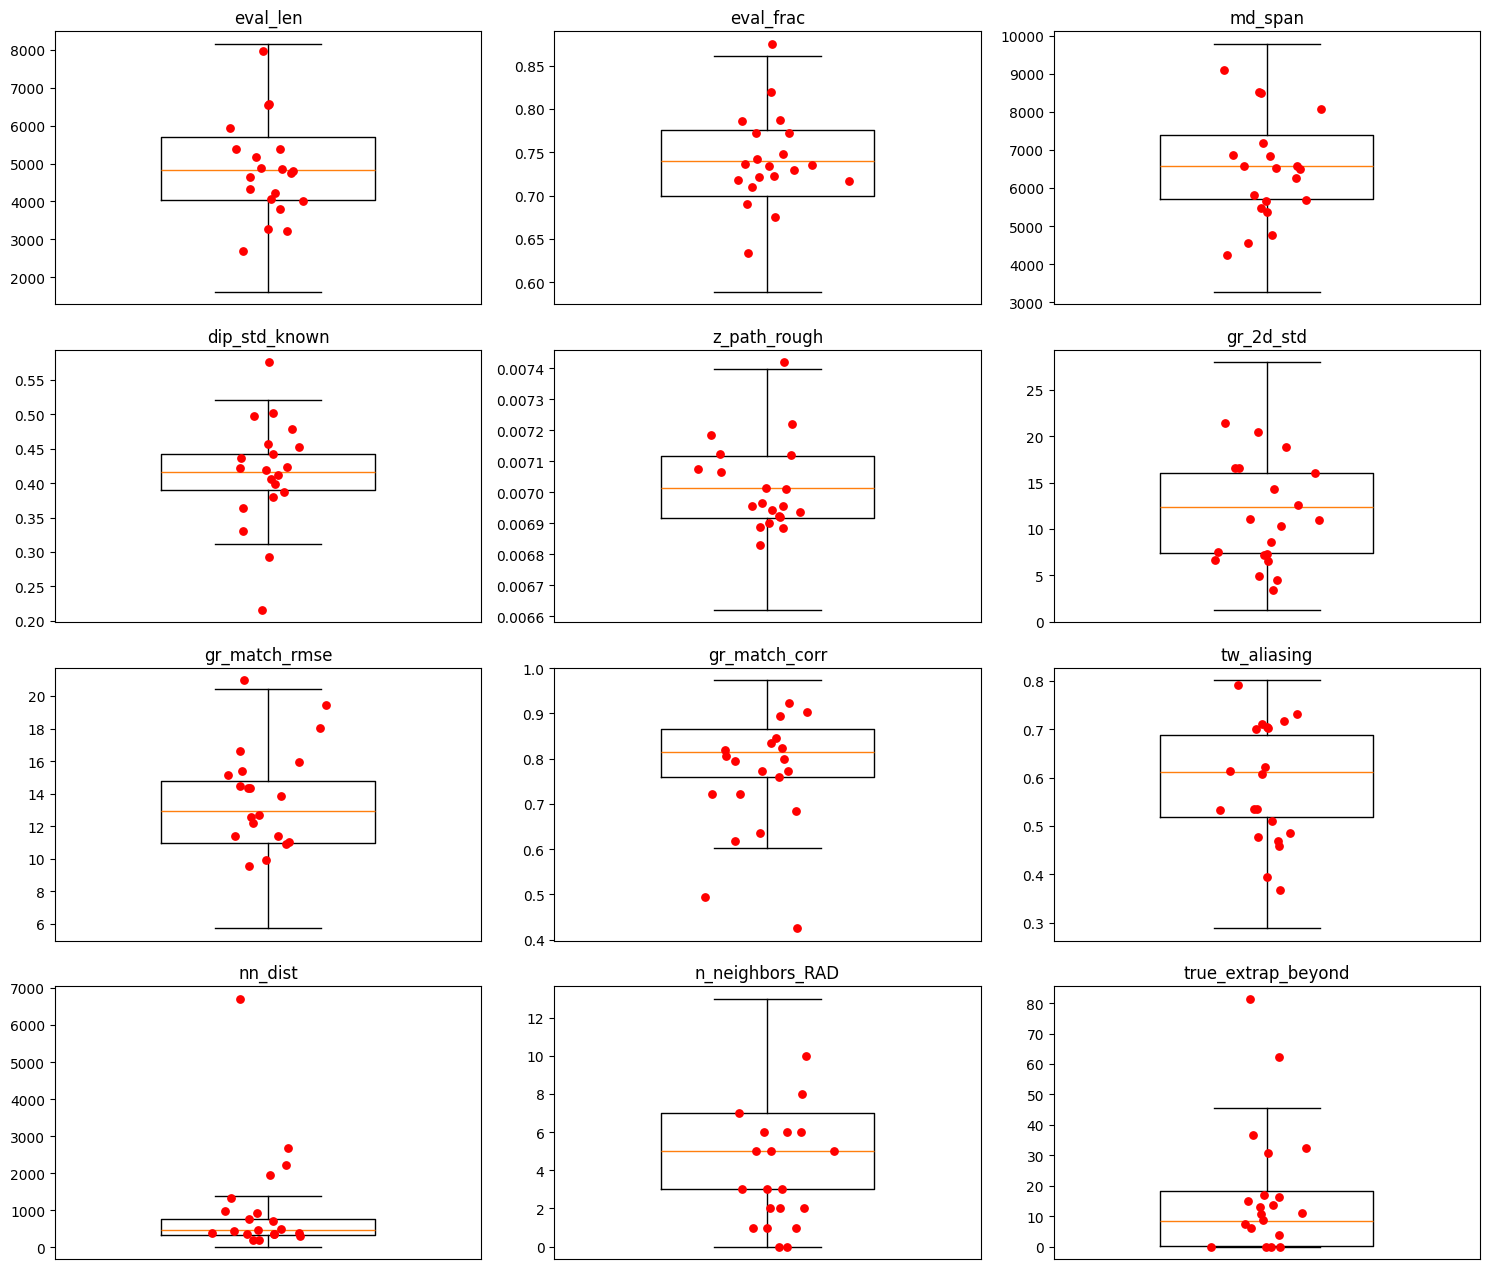

In [4]:
# ===== 分布の可視化(箱ひげ=普通, 赤点=硬い核) =====
PLOT = ["eval_len","eval_frac","md_span","dip_std_known","z_path_rough","gr_2d_std",
        "gr_match_rmse","gr_match_corr","tw_aliasing","nn_dist","n_neighbors_RAD",
        "true_extrap_beyond"]
PLOT = [c for c in PLOT if c in df.columns]
n = len(PLOT); ncol = 3; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.2 * nrow))
for ax, c in zip(np.ravel(axes), PLOT):
    rest = df.loc[~df.is_hard, c].dropna().to_numpy()
    ax.boxplot(rest, vert=True, widths=0.5, showfliers=False, positions=[1])
    yv = df.loc[df.is_hard, c].to_numpy(float)
    xv = np.random.normal(1, 0.05, len(yv))
    ax.scatter(xv, yv, c="red", s=28, zorder=3, label="hard")
    ax.set_title(c); ax.set_xticks([])
for ax in np.ravel(axes)[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

In [5]:
# ===== 硬い核 各坑井の詳細(oracle降順) =====
show = ["well","oracle","eval_len","eval_frac","md_span","dip_known","dip_std_known",
        "gr_match_rmse","gr_match_corr","tw_aliasing","nn_dist","n_neighbors_RAD",
        "true_eval_outside_frac","true_extrap_beyond","true_dip_change"]
show = [c for c in show if c in df.columns]
hard_tbl = df[df.is_hard][show].sort_values("oracle", ascending=False)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
print(hard_tbl.to_string(index=False))

# 全体中央値も並べて、各坑井がどの軸で外れているか目視
print("\n--- 全坑井 中央値(参考) ---")
print(df[show[2:]].median().round(3).to_string())

    well  oracle  eval_len  eval_frac  md_span  dip_known  dip_std_known  gr_match_rmse  gr_match_corr  tw_aliasing     nn_dist  n_neighbors_RAD  true_eval_outside_frac  true_extrap_beyond  true_dip_change
b8c49c1a    28.8      4319   0.690598   6253.0   0.479311       0.423225      12.196467       0.844474     0.730786  503.859487                2                0.410975               10.71        -0.474689
113011eb    27.7      3272   0.717387   4560.0   0.235573       0.329908      12.659955       0.721668     0.367596  766.548442                2                0.490526               13.59        -0.238688
91db7070    26.9      4073   0.721396   5645.0   0.371362       0.435978      14.485354       0.822468     0.509288  714.145020                5                1.000000               62.39        -0.353652
a2e8e7f6    20.7      4760   0.818995   5811.0   0.483146       0.363143      11.011532       0.834763     0.532169  978.086502                3                0.245588        

In [6]:
# ===== グローバル水平化prior検証: flat-hold / dip減衰 / 線形外挿 を overall RMSE で比較 =====
# 仮説: ラテラルは普遍的に水平化(dip_eval≈0)。known dip を外挿(linear)すると行き過ぎ → flat/減衰が勝つはず。
# 真値TVT(train限定)で overall(全行プール)RMSE を比較。dipは末尾30点の TVT_input~MD 傾き(PFのdip_prior相当)。
TAUS = [150, 300, 600, 1200, 2400]
methods = ["flat", "linear"] + [f"damp{t}" for t in TAUS]

def eval_resids(wid):
    hw = pd.read_csv(DATA / f"{wid}__horizontal_well.csv")
    if "TVT" not in hw.columns: return None
    kn = hw[hw["TVT_input"].notna()]; ev = hw[hw["TVT_input"].isna()]
    if len(kn) < 5 or len(ev) < 1: return None
    kmd = kn["MD"].to_numpy(float); ktvt = kn["TVT_input"].to_numpy(float)
    emd = ev["MD"].to_numpy(float); etrue = ev["TVT"].to_numpy(float)
    ok = np.isfinite(etrue); emd, etrue = emd[ok], etrue[ok]
    if len(etrue) < 1: return None
    last_tvt = float(ktvt[-1]); md_last = float(kmd[-1])
    t = kn.tail(30)
    dip = _lin1(t["MD"].to_numpy(float), t["TVT_input"].to_numpy(float))[0]   # PFのdip_prior相当
    if not np.isfinite(dip): dip = 0.0
    dmd = emd - md_last
    out = {"flat": last_tvt - etrue, "linear": last_tvt + dip * dmd - etrue}
    for tau in TAUS:
        out[f"damp{tau}"] = (last_tvt + dip * tau * (1.0 - np.exp(-dmd / tau))) - etrue
    return out

pool = {"all":{m:[] for m in methods}, "hard":{m:[] for m in methods}, "rest":{m:[] for m in methods}}
perwell = {}
for w in df["well"]:
    r = eval_resids(w)
    if r is None: continue
    grp = "hard" if w in HARD else "rest"
    pw = {}
    for m in methods:
        e = r[m]; e = e[np.isfinite(e)]
        if len(e) == 0: pw[m] = np.nan; continue
        pool["all"][m].append(e); pool[grp][m].append(e)
        pw[m] = float(np.sqrt(np.mean(e**2)))
    perwell[w] = pw

def pooled(lst):
    if not lst: return np.nan
    e = np.concatenate(lst); return float(np.sqrt(np.mean(e**2)))

print("=== overall(全行プール)RMSE ===")
print(f"{'method':10s} {'all':>8s} {'hard':>8s} {'rest':>8s}")
for m in methods:
    print(f"{m:10s} {pooled(pool['all'][m]):8.3f} {pooled(pool['hard'][m]):8.3f} {pooled(pool['rest'][m]):8.3f}")

print("\n=== 硬い核20件: flat / best-damp / linear vs oracle(PF最良) ===")
rows = []
for w, orc in sorted(HARD.items(), key=lambda x: -x[1]):
    pw = perwell.get(w, {})
    dvals = [(m, pw[m]) for m in methods if m.startswith("damp") and np.isfinite(pw.get(m, np.nan))]
    bm, bv = min(dvals, key=lambda x: x[1]) if dvals else (None, np.nan)
    best_simple = np.nanmin([pw.get("flat", np.nan), bv])
    rows.append(dict(well=w, oracle=orc, flat=round(pw.get("flat", np.nan), 2),
                     best_damp=round(bv, 2), best_tau=bm, linear=round(pw.get("linear", np.nan), 1),
                     beats_oracle=("YES" if best_simple < orc else "")))
ht = pd.DataFrame(rows)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
print(ht.to_string(index=False))
nwin = int((ht["beats_oracle"] == "YES").sum())
print(f"\nflat/damp が oracle に勝つ硬い核: {nwin}/{len(ht)} 件")

=== overall(全行プール)RMSE ===
method          all     hard     rest
flat         15.910   28.571   15.440
linear      110.637   74.046  111.434
damp150      15.576   27.657   15.131
damp300      16.877   27.232   16.519
damp600      22.284   27.693   22.124
damp1200     35.005   31.703   35.087
damp2400     54.032   41.015   54.331

=== 硬い核20件: flat / best-damp / linear vs oracle(PF最良) ===
    well  oracle  flat  best_damp best_tau  linear beats_oracle
b8c49c1a    28.8  8.26       8.06  damp150    37.0          YES
113011eb    27.7  5.18       5.09  damp150    16.3          YES
91db7070    26.9 40.81       9.24 damp2400    36.4          YES
a2e8e7f6    20.7 10.70      10.84  damp150    94.0          YES
1b82b665    19.5  6.11       5.98  damp150    45.9          YES
73348914    18.5 10.69      12.57  damp150    42.0          YES
86454a6f    17.9 70.26      47.54 damp2400    22.6             
e7818f7a    17.0  6.31       4.55  damp600    18.4          YES
91b301ce    17.0 35.32      37.18 